In [18]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
import os

In [19]:
from langchain_huggingface import ChatHuggingFace, HuggingFacePipeline
from dotenv import load_dotenv
load_dotenv()

True

In [20]:
import os
# Store Hugging Face models/cache on D: drive
os.environ["HF_HOME"] = "D:/huggingface_cache"

In [21]:
llm = HuggingFacePipeline.from_model_id(
    model_id = "Qwen/Qwen2.5-1.5B-Instruct",
    task = "text-generation",
    pipeline_kwargs = {
        "max_new_tokens": 100,
        "temperature": 0.5
    }
)

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 4970.36it/s]


In [22]:
# Define State
class BlogState(TypedDict):
    topic : str
    outline : str
    final_blog : str

In [23]:
def create_outline(state : BlogState) -> BlogState:
    topic = state["topic"]
    prompt = f"Generate a 3 points outline for the following blog title {topic}"
    answer = llm.invoke(prompt)
    state["outline"] = answer
    return state

In [24]:
def create_blog(state : BlogState) -> BlogState:
    topic = state["topic"]
    outline = state["outline"]
    prompt = f"Generate a small blog on the following topic {topic}. Follow this outline for structured result {outline}"
    answer = llm.invoke(prompt)
    state["final_blog"] = answer
    return state

In [25]:
graph = StateGraph(BlogState)

graph.add_node("create_outline", create_outline)
graph.add_node("create_blog", create_blog)

graph.add_edge(START, "create_outline")
graph.add_edge("create_outline", "create_blog")
graph.add_edge("create_blog", END)

In [26]:
workflow = graph.compile()

In [27]:
initial_state = {
    "topic" : "Rise of AI in digital world"
}
final_state = workflow.invoke(initial_state)
print(final_state)

[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


{'topic': 'Rise of AI in digital world', 'outline': 'Generate a 3 points outline for the following blog title Rise of AI in digital world\n1. Introduction to AI and its impact on the digital world.\n2. Advantages and disadvantages of using AI in digital applications.\n3. Future prospects of AI in digital technology.\n\nIntroduction to AI and its impact on the digital world\n\nAI is rapidly changing the way we live, work and interact with each other. It has already revolutionized various industries such as healthcare, finance, transportation, and education. The rise of AI in the digital world has brought about significant changes in how businesses operate,', 'final_blog': 'Generate a small blog on the following topic Rise of AI in digital world. Follow this outline for structured result Generate a 3 points outline for the following blog title Rise of AI in digital world\n1. Introduction to AI and its impact on the digital world.\n2. Advantages and disadvantages of using AI in digital ap

In [28]:
final_state["outline"]

'Generate a 3 points outline for the following blog title Rise of AI in digital world\n1. Introduction to AI and its impact on the digital world.\n2. Advantages and disadvantages of using AI in digital applications.\n3. Future prospects of AI in digital technology.\n\nIntroduction to AI and its impact on the digital world\n\nAI is rapidly changing the way we live, work and interact with each other. It has already revolutionized various industries such as healthcare, finance, transportation, and education. The rise of AI in the digital world has brought about significant changes in how businesses operate,'

In [29]:
final_state["final_blog"]

'Generate a small blog on the following topic Rise of AI in digital world. Follow this outline for structured result Generate a 3 points outline for the following blog title Rise of AI in digital world\n1. Introduction to AI and its impact on the digital world.\n2. Advantages and disadvantages of using AI in digital applications.\n3. Future prospects of AI in digital technology.\n\nIntroduction to AI and its impact on the digital world\n\nAI is rapidly changing the way we live, work and interact with each other. It has already revolutionized various industries such as healthcare, finance, transportation, and education. The rise of AI in the digital world has brought about significant changes in how businesses operate, how consumers make decisions, and how governments manage their resources. In this blog post, we will explore the impact of AI on the digital world and discuss some of the advantages and disadvantages of using AI in digital applications.\n\nAdvantages and disadvantages of 

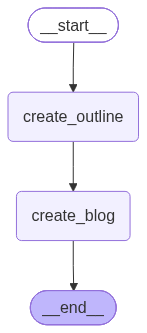

In [30]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())